# Heart Prediction
Tommy Tang <br>
Oct 11th, 2026

In [1]:
#Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.notebook import tqdm
from torchmetrics.classification import BinaryF1Score, BinaryAccuracy, BinaryRecall, BinaryPrecision
import copy

### EDA

In [2]:
df = pd.read_csv('../data/heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
#Check overview
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [4]:
#Check NAs
df.isna().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [5]:
#Check dtypes
features_num = df.select_dtypes(['int', 'float']).columns
features_cat = df.select_dtypes('object').columns
print(f'Df shape:{df.shape}')
print(features_num)
print(features_cat)

Df shape:(918, 12)
Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease'],
      dtype='str')
Index(['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'], dtype='str')


/var/folders/d7/9pmjhtyd2xz2mwzknlxx9j8r0000gn/T/ipykernel_79837/1853132752.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  features_cat = df.select_dtypes('object').columns


In [6]:
#OHE categorical features
df_ohe = pd.get_dummies(df, dtype=int)
features_ohe = df_ohe.select_dtypes(['int', 'float']).columns
print(features_ohe)
print(f'Numerical features: {len(features_ohe)}')

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_F', 'Sex_M', 'ChestPainType_ASY',
       'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA',
       'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_N', 'ExerciseAngina_Y', 'ST_Slope_Down',
       'ST_Slope_Flat', 'ST_Slope_Up'],
      dtype='str')
Numerical features: 21


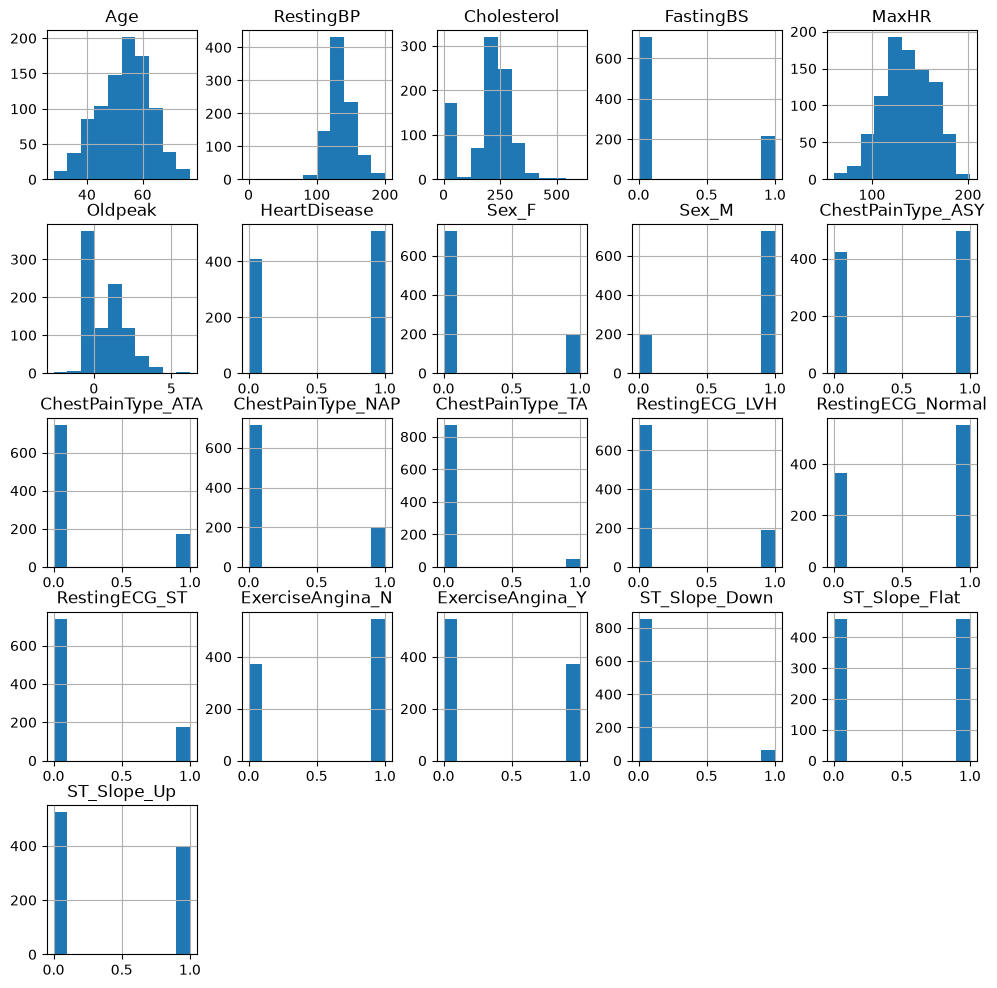

In [7]:
#Examine distributions
df_ohe.hist(figsize=(12,12));

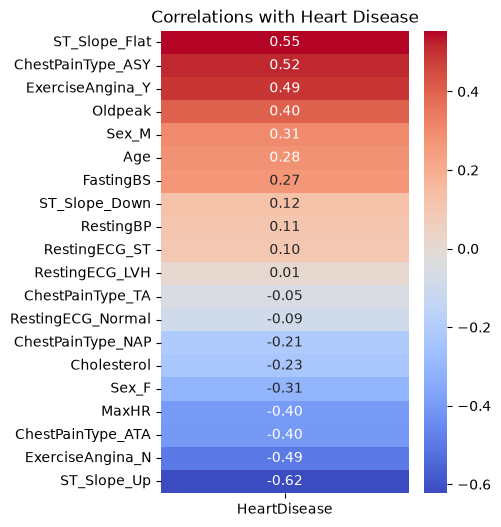

In [8]:
#Examine correlations
correlations = df_ohe.corr()[['HeartDisease']]
correlations = correlations.drop(index='HeartDisease')
plt.figure(figsize=(4,6))
plt.title('Correlations with Heart Disease')
sns.heatmap(correlations.sort_values('HeartDisease', ascending=False), cmap='coolwarm', annot=True, fmt='.2f');

### Preprocessing

In [9]:
from sklearn.model_selection import train_test_split
#No need for data cleansing, data imputation, or data balancing for this dataset.
#Separate into features and labels
X = df.copy()
y = X.pop('HeartDisease')

#Separate by feature type
features_num = X.select_dtypes(include=['int', 'float']).columns
features_cat = X.select_dtypes(include=['object', 'string']).columns

#Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
#Define preprocessing
preprocessor = ColumnTransformer([('numerical', StandardScaler(), features_num), ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_cat)])

#Apply preprocessing
print(f"Shape before: {X_train.shape}")
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)
print(f"Shape after: {X_train.shape}")

Shape before: (734, 11)
Shape after: (734, 20)


### Training

In [11]:
#Dataset Class
class HeartDataset(Dataset):
    def __init__(self, data, label):
        self.data = torch.tensor(data, dtype=torch.float32)          
        self.labels = torch.tensor(label.values, dtype=torch.float32).unsqueeze(1)
        
    def __len__(self):
        return len(self.data)
            
    def __getitem__(self, idx):
        return self.data[idx], self.labels[idx]

In [12]:
#Model Class
class HeartModel(nn.Module):
    def __init__(self, input_size, dropout):
        super().__init__()
        self.fc1 = nn.Linear(input_size, 256)
        self.fc2 = nn.Linear(256, 256)
        self.out = nn.Linear(256, 1)
        self.dropout=nn.Dropout(p=dropout)
        
    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        x = torch.relu(self.fc2(x))
        return self.out(x)

In [13]:
#Initialize everything
model = HeartModel(X_train.shape[1], 0)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters())

train_loader = DataLoader(HeartDataset(X_train, y_train), batch_size=64, shuffle=True)
test_loader = DataLoader(HeartDataset(X_test, y_test), batch_size=64)


In [14]:
def train(model, dataloader, loss_fn, optimizer):
    model.train()
    total_loss = 0
    f1, acc, recall, precision = BinaryF1Score(), BinaryAccuracy(), BinaryRecall(), BinaryPrecision()
    
    #Training Loop
    for X_batch, y_batch in train_loader:
        pred = model(X_batch) 
        loss = loss_fn(pred, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * len(X_batch)
        pred_binary = torch.sigmoid(pred) > 0.5
        f1.update(pred_binary, y_batch) 
        acc.update(pred_binary, y_batch)
        recall.update(pred_binary, y_batch)
        precision.update(pred_binary, y_batch)
        
    #Compute final metrics
    train_f1 = f1.compute().item()
    train_accuracy = acc.compute().item()
    train_recall =  recall.compute().item()
    train_precision = precision.compute().item()
    train_loss = total_loss / len(dataloader.dataset)
                    
    return train_loss, train_f1, train_accuracy, train_recall, train_precision
   

In [15]:
def evaluate(model, dataloader, loss_fn):
    model.eval()
    total_loss = 0.0
    f1, acc, recall, precision = BinaryF1Score(), BinaryAccuracy(), BinaryRecall(), BinaryPrecision()
    
    #No gradients needed during training loop
    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            pred = model(X_batch)
            loss = loss_fn(pred, y_batch)
            total_loss += loss.item() * len(X_batch)
            
            pred_binary = torch.sigmoid(pred) > 0.5
            f1.update(pred_binary, y_batch) 
            acc.update(pred_binary, y_batch)
            recall.update(pred_binary, y_batch)
            precision.update(pred_binary, y_batch)
            
    #Compute final metrics
    test_f1 = f1.compute().item()
    test_accuracy = acc.compute().item()
    test_recall =  recall.compute().item()
    test_precision = precision.compute().item()
    test_loss = total_loss / len(dataloader.dataset)
    
    return test_loss, test_f1, test_accuracy, test_recall, test_precision

In [22]:
history = []
results = []
best_test_loss, best_test_accuracy, best_test_f1, best_state, patience, bad_epochs = float('inf'), 0, 0, None, 10, 0

for epoch in range(200):
    train_loss, train_f1, train_accuracy, train_recall, train_precision = train(model, train_loader, loss_fn, optimizer)
    test_loss, test_f1, test_accuracy, test_recall, test_precision = evaluate(model, test_loader, loss_fn)
    
    history.append({
        'loss': train_loss,
        'accuracy': train_accuracy,
        'f1': train_f1,
        'recall': train_recall,
        'precision': train_precision,
        'test_loss': test_loss,
        'test_accuracy': test_accuracy,
        'test_f1': test_f1,
        'test_recall': test_recall,
        'test_precision': test_precision
    })
    
    print(f"epoch {epoch+1:3d}: train_loss {train_loss:.4f}  test_loss {test_loss:.4f}  "
          f"train_f1 {train_f1:.3f}  test_f1 {test_f1:.3f}")

    if test_accuracy > best_test_accuracy:
        best_test_accuracy = test_accuracy
    
    if test_f1 > best_test_f1:
        best_test_f1 = test_f1

    if test_loss < best_test_loss:
        best_test_loss, bad_epochs = test_loss, 0
        best_state = copy.deepcopy(model.state_dict())
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

results.append({'best_test_accuracy': best_test_accuracy, 'best_test_f1': best_test_f1, 'best_test_loss': best_test_loss})
model.load_state_dict(best_state)

epoch   1: train_loss 0.2301  test_loss 0.3211  train_f1 0.913  test_f1 0.888
epoch   2: train_loss 0.2165  test_loss 0.3279  train_f1 0.923  test_f1 0.890
epoch   3: train_loss 0.2131  test_loss 0.3394  train_f1 0.920  test_f1 0.896
epoch   4: train_loss 0.2068  test_loss 0.3338  train_f1 0.925  test_f1 0.890
epoch   5: train_loss 0.1974  test_loss 0.3351  train_f1 0.928  test_f1 0.874
epoch   6: train_loss 0.1902  test_loss 0.3765  train_f1 0.925  test_f1 0.888
epoch   7: train_loss 0.1973  test_loss 0.3657  train_f1 0.930  test_f1 0.874
epoch   8: train_loss 0.1815  test_loss 0.3597  train_f1 0.932  test_f1 0.889
epoch   9: train_loss 0.1780  test_loss 0.3724  train_f1 0.933  test_f1 0.887
epoch  10: train_loss 0.1692  test_loss 0.3692  train_f1 0.943  test_f1 0.877
epoch  11: train_loss 0.1622  test_loss 0.3824  train_f1 0.945  test_f1 0.866
Early stopping at epoch 11


<All keys matched successfully>

Best test accuracy: 0.897
Best test F1: 0.908


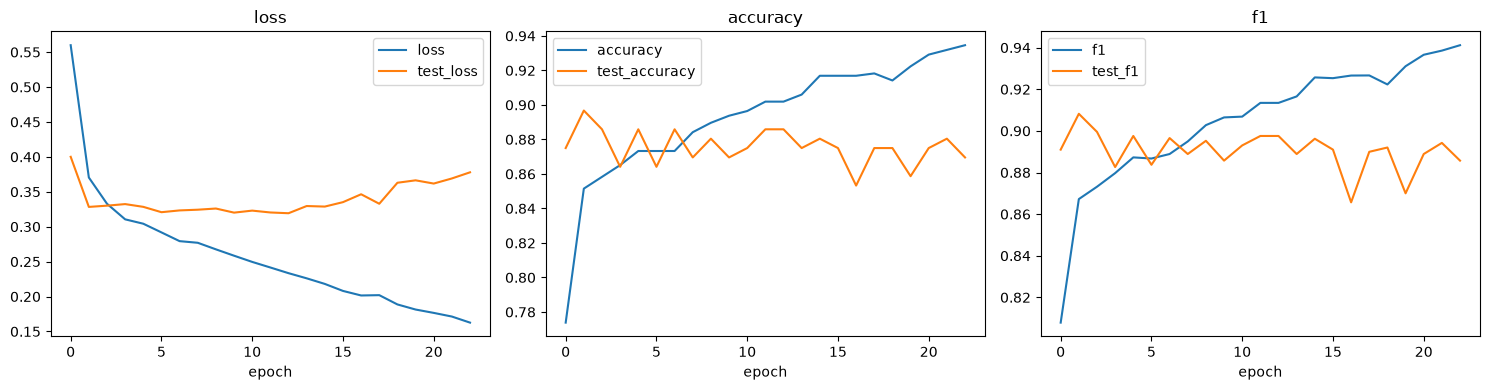

In [ ]:
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ['loss', 'accuracy', 'f1']):
    history_df[[metric, f'test_{metric}']].plot(ax=ax, title=metric)
    ax.set_xlabel('epoch')
plt.tight_layout()

print(f"Best test accuracy: {history_df['test_accuracy'].max():.3f}")
print(f"Best test F1: {history_df['test_f1'].max():.3f}")


In [ ]:
history

[{'loss': 0.5598678056972878,
  'accuracy': 0.7738419771194458,
  'f1': 0.8078703880310059,
  'recall': 0.8596059083938599,
  'precision': 0.7620087265968323,
  'test_loss': 0.4000681392524553,
  'test_accuracy': 0.875,
  'test_f1': 0.8909952640533447,
  'test_recall': 0.9215686321258545,
  'test_precision': 0.8623853325843811},
 {'loss': 0.3704516987547238,
  'accuracy': 0.8514986634254456,
  'f1': 0.8672350645065308,
  'recall': 0.8768472671508789,
  'precision': 0.8578312993049622,
  'test_loss': 0.3283343379912169,
  'test_accuracy': 0.89673912525177,
  'test_f1': 0.9082125425338745,
  'test_recall': 0.9215686321258545,
  'test_precision': 0.8952381014823914},
 {'loss': 0.3328589210718139,
  'accuracy': 0.8583106398582458,
  'f1': 0.8731707334518433,
  'recall': 0.8817734122276306,
  'precision': 0.8647342920303345,
  'test_loss': 0.3301231692666593,
  'test_accuracy': 0.885869562625885,
  'test_f1': 0.89952152967453,
  'test_recall': 0.9215686321258545,
  'test_precision': 0.87850